### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 2: Manifold Learning
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Manifold

¿Qué es un Manifold?

## Entendiendo el "Manifold"

Imagine una pequeña hormiga caminando por una superficie en 3 dimensiones que podría tener curvas o incluso agujeros, pero desde el punto de vista de la hormiga dondequiera que camine se ve como un plano.

<div align="center">
    <img src="img/hormiga.png" alt="" width="30%" align="center" />
</div>

## Ejemplos de Manifolds

En palabras simples, podemos pensar en un Manifold como una superficie de cualquier forma, no necesariamente un plano, sin puntas o bordes pronunciados como un cubo.

<div align="center">
    <img src="img/manifolds.png" alt="" width="30%" align="center" />
</div>

## Manifold Learning

Entonces, ¿Qué es el Manifold Learning?

<div align="center">
    <img src="img/manifold.png" alt="" width="30%" align="center" />
</div>

Encontrar o aprender $f(\cdot)$, se conoce como "Manifold Learning".

In [1]:
from sklearn import manifold

In [2]:
import matplotlib.pyplot as plt

In [3]:
# pip install plotly
import plotly.express as px

In [4]:
import pandas as pd

In [5]:
from sklearn import datasets

In [6]:
def plot_2d(points, points_color, title):
    plt.scatter(points[:, 0], points[:, 1], c=points_color, cmap=plt.cm.plasma)
    plt.title(title, size=16)
    plt.ylabel("Dimensión 1")
    plt.xlabel("Dimensión 2")
    plt.xticks([])
    plt.yticks([])
    plt.show()

In [7]:
S_points, S_color = datasets.make_s_curve(1500, random_state=0)
df = pd.DataFrame({'x':S_points[:,0], 'y':S_points[:,1], 'z':S_points[:,2],'c':S_color})

In [8]:
fig = px.scatter_3d(df, df.x, df.y, df.z, color = df.c)
fig.show()

# Reducción de dimensionalidad

<div align="center">
    <img src="img/PCA.png" alt="" width="50%" align="center" />
</div>

# Principal component analysis (PCA)

Proyecta los datos en dirección de las componentes principales (vectores que maximizan la varianza) para preservar tanta variación de los datos como sea posible.

PCA es una transformación lineal y falla al encontrar la estructura no lineal en los datos.

In [9]:
from sklearn.decomposition import PCA

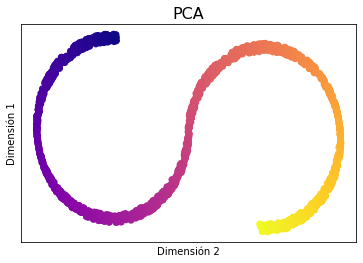

In [10]:
pca = PCA(n_components = 2)
S_pca = pca.fit_transform(S_points)
plot_2d(S_pca, S_color, "PCA")

# Isomap Embedding

Reducción de dimensionalidad no lineal a través de Isometric Mapping (mapeo que conserva distancias). Isomap busca un Embedding de menor dimensión que mantenga distancias geodésicas entre todos los puntos.

La distancia geodésica se calcula en un espacio esférico 3D como la distancia a lo largo de la superficie curvada del mundo.

<div align="center">
    <img src="img/linea-geodesica.png" alt="" width="50%" align="center" />
</div>

## Distancia Euclidiana y Geodésica

<div align="center">
    <img src="img/euc-geo.jpg" alt="" width="30%" align="center" />
</div>

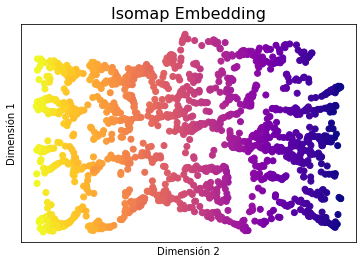

In [11]:
isomap = manifold.Isomap(n_components=2)
S_isomap = isomap.fit_transform(S_points)

plot_2d(S_isomap, S_color, "Isomap Embedding")

# Locally Linear Embedding

La incrustación lineal local (LLE) busca una proyección de menor dimensión de los datos que preserva las distancias dentro de los vecindarios locales. Se puede considerar como varios PCA locales que se comparan globalmente para encontrar la mejor representación no lineal.

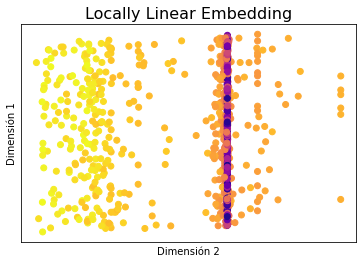

In [12]:
lle = manifold.LocallyLinearEmbedding(n_components=2)
S_lle = lle.fit_transform(S_points)

plot_2d(S_lle, S_color, "Locally Linear Embedding")

# Modified Locally Linear Embedding

Agrega una ponderación diferente en cada vecindario.

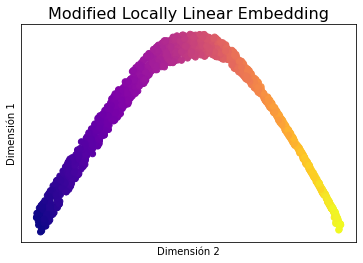

In [13]:
m_lle = manifold.LocallyLinearEmbedding(n_components=2, method='modified')
S_m_lle = m_lle.fit_transform(S_points)

plot_2d(S_m_lle, S_color, "Modified Locally Linear Embedding")

# Local Tangent Space Alignment

Aunque técnicamente no es una variante de LLE, la alineación del espacio tangente local (LTSA) es algorítmicamente lo suficientemente similar a LLE como para incluirla en esta categoría. En lugar de centrarse en preservar las distancias de los vecindarios como en LLE, LTSA busca caracterizar la geometría local en cada vecindario a través de su espacio tangente y realiza una optimización global para alinear estos espacios tangentes locales para aprender el Embedding.

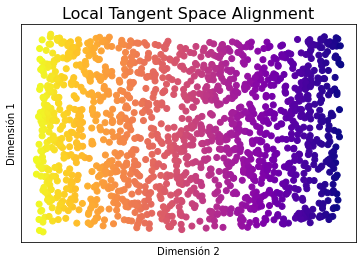

In [14]:
ltsa = manifold.LocallyLinearEmbedding(n_components=2, method='ltsa')
S_ltsa = ltsa.fit_transform(S_points)

plot_2d(S_ltsa, S_color, "Local Tangent Space Alignment")

# Multidimensional scaling

El escalado multidimensional (MDS) busca una representación de baja dimensión de los datos en la que las distancias respeten bien las distancias en el espacio original de alta dimensión.

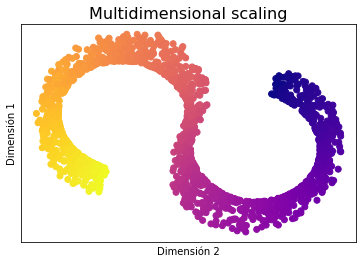

In [15]:
md_scaling = manifold.MDS(n_components=2)
S_scaling = md_scaling.fit_transform(S_points)

plot_2d(S_scaling, S_color, "Multidimensional scaling")

# Spectral Embedding 

Esta implementación utiliza los vectores propios del Laplaciano obtenidos de una descomposición espectral para generar una representación de baja dimensión de los datos.

In [16]:
from sklearn.manifold import SpectralEmbedding

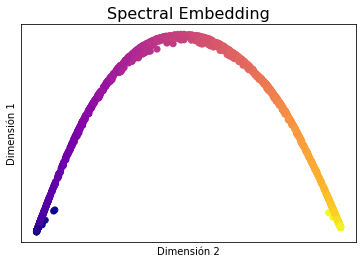

In [17]:
spectral = SpectralEmbedding(n_components=2, affinity='nearest_neighbors')
S_spectral = spectral.fit_transform(S_points)

plot_2d(S_spectral, S_color, "Spectral Embedding")

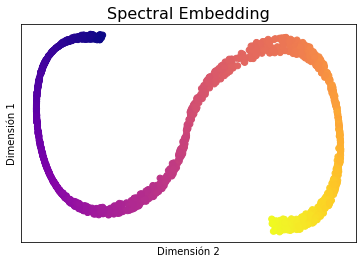

In [18]:
spectral = SpectralEmbedding(n_components=2, affinity='rbf')
S_spectral = spectral.fit_transform(S_points)

plot_2d(S_spectral, S_color, "Spectral Embedding")

# T-distributed Stochastic Neighbor Embedding

Consiste en crear una distribución de probabilidad que represente las similitudes entre vecinos en un espacio de gran dimensionalidad y reproducirla en un espacio de menos dimensiones. Por lo tanto, a diferencia de PCA, es no-lineal, siendo capaz de preservar la estructura local de los datos. La Perplexity corresponde al tamaño del vecindario, por ende, a mayor valor, mayor información no-local se retiene.

<div align="center">
<img src="img/tSNE.png" alt="" width="50%" align="center" />
</div>

In [19]:
from sklearn.manifold import TSNE

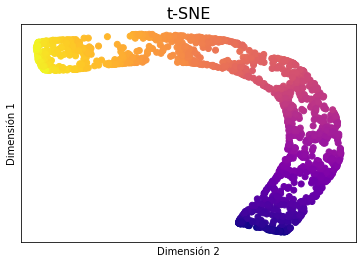

In [20]:
t_sne = TSNE(n_components=2, perplexity=30, init="random", n_iter=250, random_state=0, learning_rate='auto')
S_t_sne = t_sne.fit_transform(S_points)

plot_2d(S_t_sne, S_color, "t-SNE")

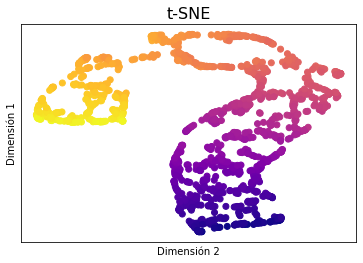

In [21]:
t_sne = TSNE(n_components=2, perplexity=8, init="random", n_iter=250, random_state=0, learning_rate='auto')
S_t_sne = t_sne.fit_transform(S_points)

plot_2d(S_t_sne, S_color, "t-SNE")

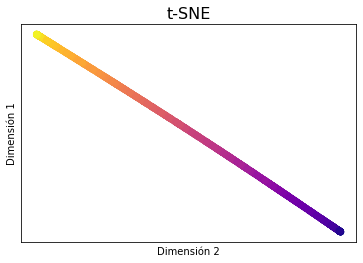

In [22]:
t_sne = TSNE(n_components=2, perplexity=100, init="random", n_iter=250, random_state=0, learning_rate='auto')
S_t_sne = t_sne.fit_transform(S_points)

plot_2d(S_t_sne, S_color, "t-SNE")

# UMAP

Uniform Manifold Approximation and Projection (UMAP) es una técnica de reducción de dimensionalidad no-lineal que aprende la estructura del Manifold en el espacio de alta dimensionalidad a través de un grafo de vecinos más cercanos y posteriormente lo proyecta para generar una representación de baja dimensionalidad. 

<div align="center">
<img src="img/grafoKNN.png" alt="" width="30%" align="center" />
</div>

In [23]:
#pip install umap-learn

In [24]:
import warnings
warnings.filterwarnings('ignore')

In [25]:
from umap import UMAP

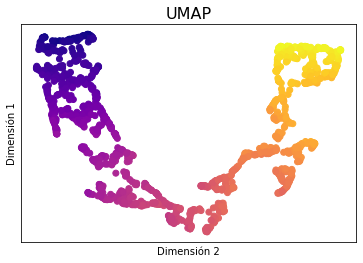

In [26]:
umap = UMAP(n_components=2)
S_umap = umap.fit_transform(S_points)

plot_2d(S_umap, S_color, "UMAP")

# Modelos 3D

## Mammoth 50K

In [27]:
df = pd.read_csv('data/mammoth50k.csv')

In [28]:
fig = px.scatter_3d(df, df.X, df.Y, df.Z)
fig.show()

## Proyección 3d

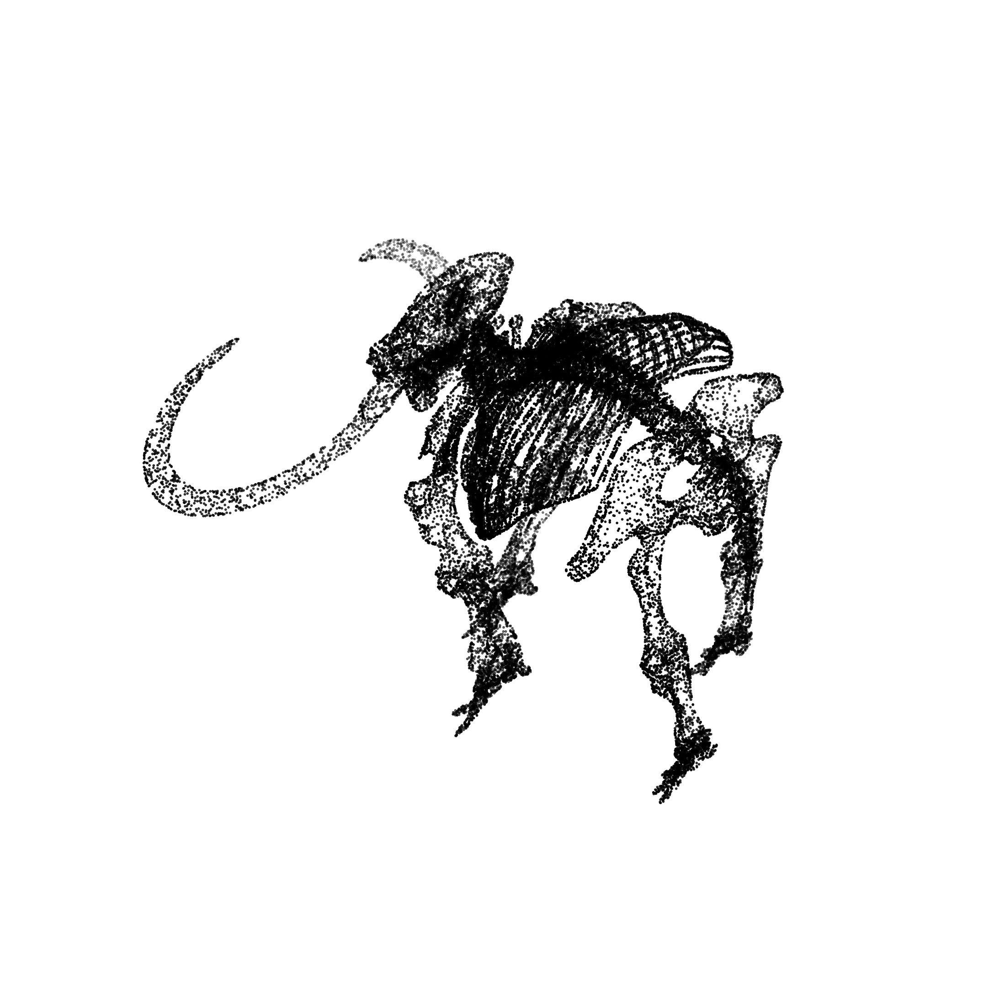

In [29]:
fig = plt.figure(figsize=(40,40))
ax = fig.add_subplot(111, projection='3d')
ax.set_axis_off()
ax.scatter(df.X, df.Y, df.Z, s=20, c='black')
plt.show()

## Cambiando el ángulo

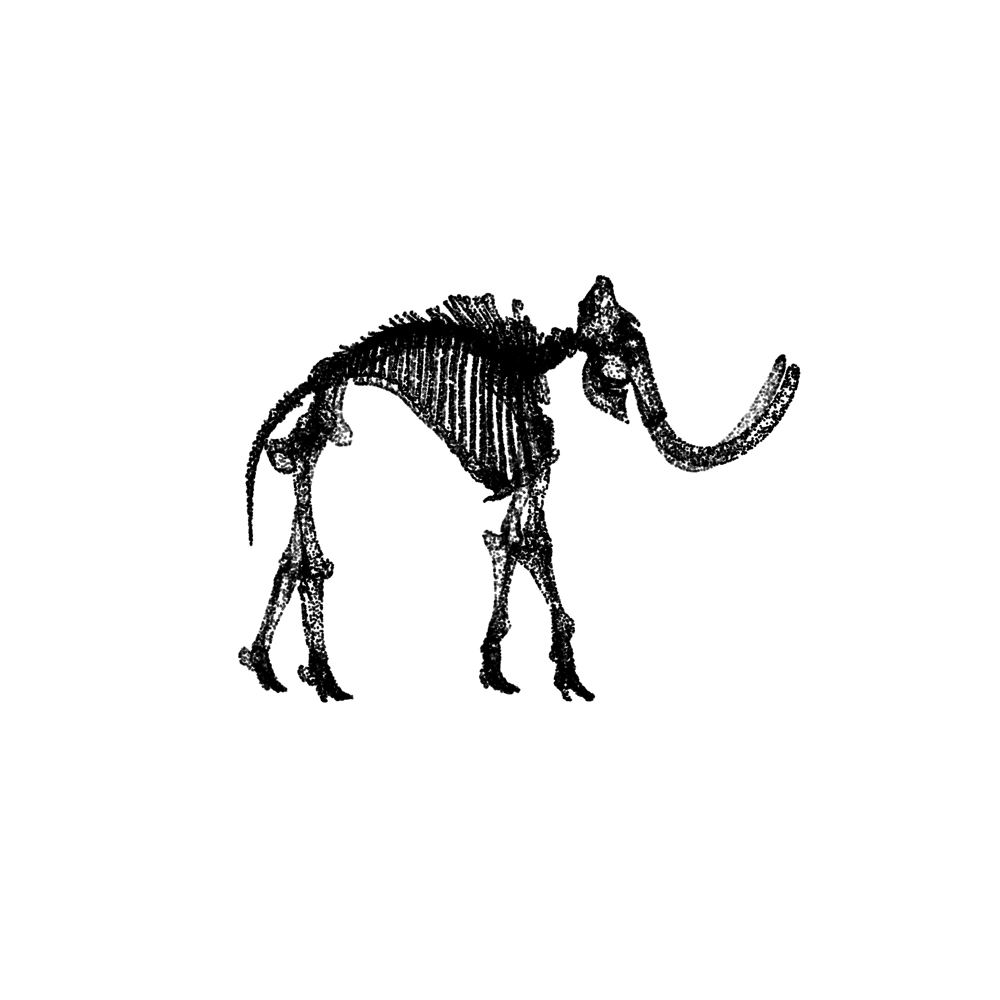

In [30]:
fig = plt.figure(figsize=(40,40))
ax = fig.add_subplot(111, projection='3d')
ax.set_axis_off()
ax.scatter(df.X, df.Y, df.Z, s=20, c='black')
ax.view_init(0, 90)
plt.show()

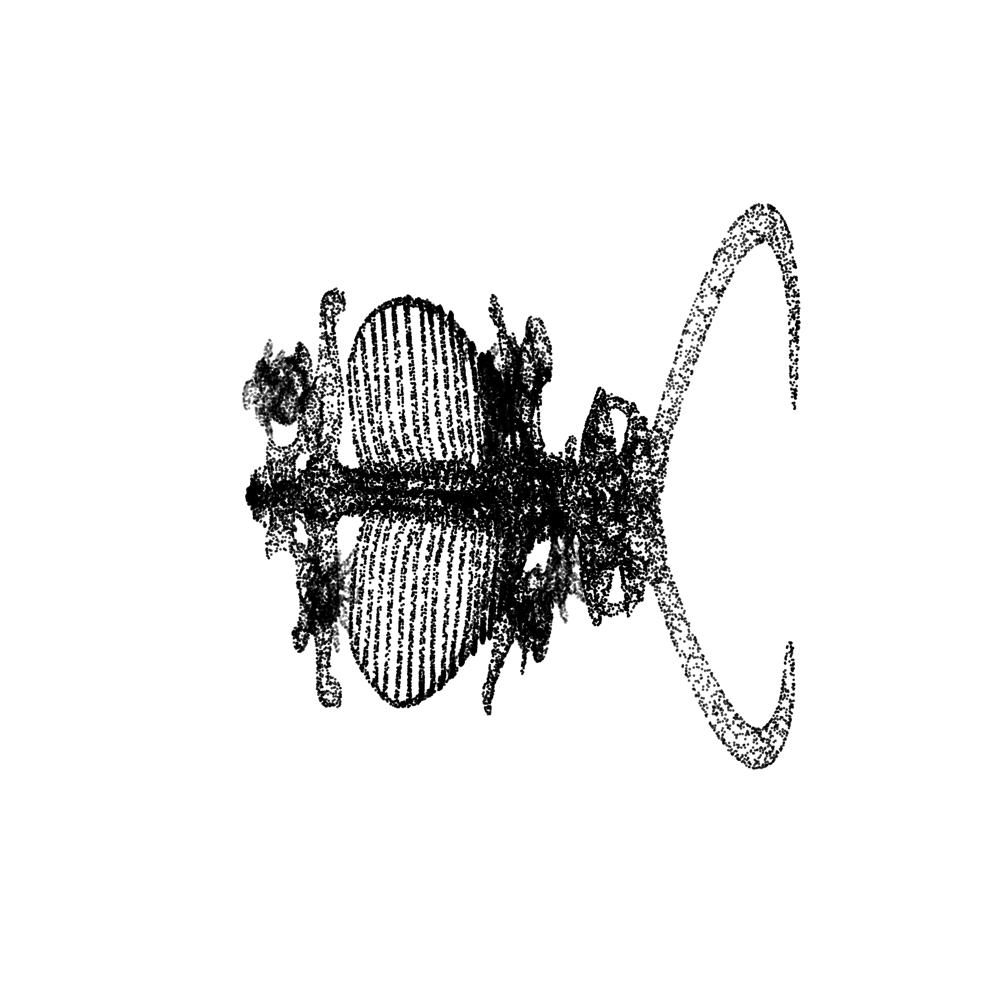

In [31]:
fig = plt.figure(figsize=(40,40))
ax = fig.add_subplot(111, projection='3d')
ax.set_axis_off()
ax.scatter(df.X, df.Y, df.Z, s=20, c='black')
ax.view_init(90, 90)
plt.show()

## Mammoth 10K

Desde ahora, vamos a trabajar con el dataset Mammoth 10K por motivos de eficiencia.

In [32]:
df = pd.read_csv('data/mammoth10k.csv')

## Reducción de dimensionalidad

In [33]:
algorithms = {
    'PCA': PCA(n_components=2),    
    'Spectral': SpectralEmbedding(n_components=2),
    't-SNE': TSNE(n_components=2, init="random", n_iter=250, random_state=0, learning_rate='auto'),
    'UMAP': UMAP(n_components=2)
}
results = {}
for name in algorithms:
    algorithm = algorithms[name]
    embedding = algorithm.fit_transform(df.values)
    results[name] = embedding

In [34]:
def add_2d_scatter(ax, points, title=None):
    x, y = points.T
    ax.scatter(x, y)
    ax.set_title(title)
    ax.set_axis_off()

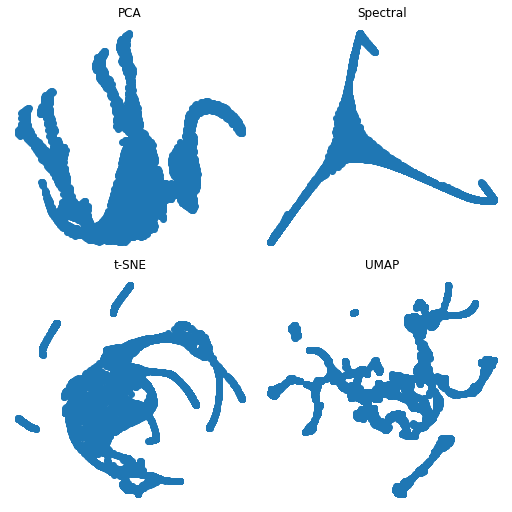

In [35]:
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(7, 7), facecolor="white", constrained_layout=True)
for ax, name in zip(axs.flat, results):
    embedding = results[name]
    add_2d_scatter(ax, embedding, name)
plt.show()

## Zoom a UMAP

In [36]:
def zoom_2d(algorithm, size=15):
    plt.figure(figsize=(size,size),facecolor='w')
    plt.axis('off')
    plt.scatter(results[algorithm][:, 0], results[algorithm][:, 1], s=2.5, c='black')
    plt.show()

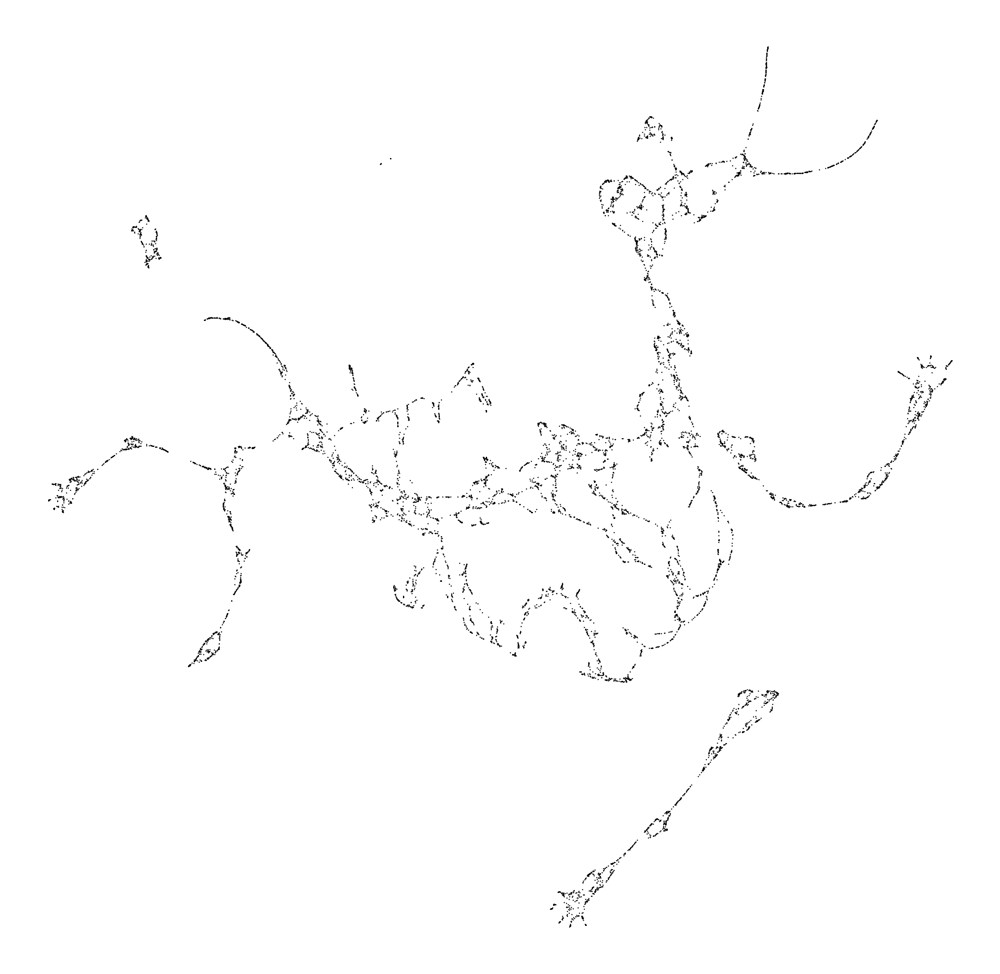

In [37]:
zoom_2d('UMAP', 40)